# AI 221 Machine Exercise 2
## Problem 1 - Palmer Penguin Species Dat Set
#### by Quiel Andrew I. Quiwa and Joel Paolo C. Salvador

In this project, we will be analyzing a dataset containing 345 samples of penguins from the Palmer Archipelago in Antarctica. The dataset contains four numerical features: culmen length, culmen depth, flipper length, and body mass index.

The culmen is the upper part of a penguin's beak. Each species of penguin has a distinct culmen that can be described in terms of the four numerical features mentioned. We will check below if an SVC model will be able to accurately predict the species of penguin in a test dataset using only the culmen length and the flipper length.

In [ ]:
# Import pandas, numpy, matplotlib, seaborn, and scikit-learn libraries for data manipulation, visualization, and machine learning tasks.

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.svm import SVC
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score, f1_score

In [ ]:
# Read the dataset using pandas and display summary statistics to understand the distribution of the data.
penguins = pd.read_csv('penguins_size.csv')
penguins.describe()

,culmen_length_mm,culmen_depth_mm,flipper_length_mm,body_mass_g
count,342.000000,342.000000,342.000000,342.000000
mean,43.921930,17.151170,200.915205,4201.754386
std,5.459584,1.974793,14.061714,801.954536
min,32.100000,13.100000,172.000000,2700.000000
25%,39.225000,15.600000,190.000000,3550.000000
50%,44.450000,17.300000,197.000000,4050.000000
75%,48.500000,18.700000,213.000000,4750.000000
max,59.600000,21.500000,231.000000,6300.000000


#### Part 1 - Seaborn Pair Plot

Using the Seaborn library's pair plot, we will visualize the 4 numerical features of the dataset with the hue set to the penguin species below. Observations will be added as a markdown cell after the plot

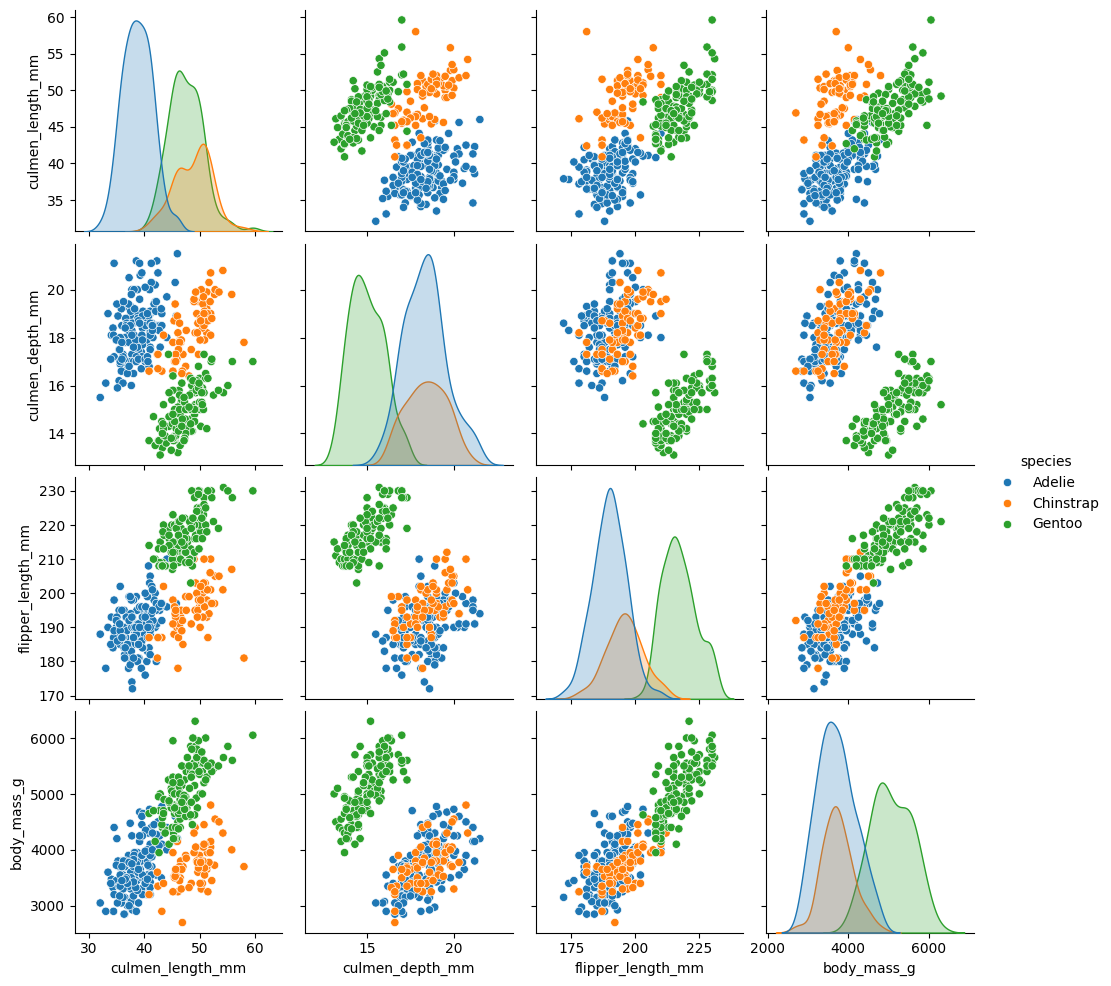

In [ ]:
sns.pairplot(
    penguins[['culmen_length_mm', 'culmen_depth_mm', 'flipper_length_mm', 'body_mass_g', 'species']].dropna(),
    hue='species'
)
plt.show()

#### Seaborn plot observations

Based on the plot distributions:
1. Adelie species typically have short but deep culmens as shown in the plots for culmen length and depth. The distribution of Adelie species with culmen length between 35-40 mm and culmen depth of about 18-20mm are high. Their flippers on the other hand are shorter (mostly about 180-200mm), and their body mass is lighter at roughly 3000-4000g.

2. Gentoo species on the other hand have longer (appox. 45-55mm) but shallow ( approx. 12-16mm) culmens, their flippers are longer (approx. 210-230mm), and their body mass is heavier (approx. 4800-6000g). Gentoo species seem to be easy to classify since the distribution plots clearly show a distinction with respect to all of their characteristics.

3. Chinstrap species have overlapping characteristics with both Adelie and Gentoo. Similar to Gentoo, the distribution plots show that Chinstrap species have longer culmen lengths similar to Gentoo, but has deeper culmens, smaller flippers, and lower body mass similar to Adelie. 


4. The scatter plots in each row also validate the claims made from the plot distributions. Chinstrap overlaps with the other species in terms of the characterstics mentioned, making it potentially difficult to classify. Visually, there seems to be a positive correlation between culmen length and flipper length, body mass and flipper length, and culmen length and body mass. This means that penguins with larger flippers are heavier, penguins with longer culmens have longer flippers, and penguins with longer culmens are also heavier. Moving forward, we will be classifying the penguins only using the culmen length and the flipper length

#### Pipeline Development

In the pipeline and model training developed below, we cleaned the dataset first since there were some "NaN" values and to also make sure that we will only be using the culmen length and the flipper length.

As required by the problem as well, the samples were split into 75% training and 25% testing data at random with stratification. Afterwards, a pipeline with standard scaler and SVC was used to train the model.

In this problem, we selected an RBF kernel for the SVC as it can capture non-linear relationships in the data, which is likely given the nature of the features and classes in the penguin dataset.

In [ ]:
penguins_clean = penguins[['culmen_length_mm', 'flipper_length_mm', 'species']].dropna()

X = penguins_clean[['culmen_length_mm', 'flipper_length_mm']]
y = penguins_clean['species']

# Split the data into 75% training and 25% testing
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=42, stratify=y)


# Build a pipeline with Standard scaler and SVC
pipeline = make_pipeline(StandardScaler(), SVC(kernel='rbf', C=1, gamma='scale', random_state=42))

# Train the model using the training data
pipeline.fit(X_train, y_train)

# Predict the test set results
y_train_pred = pipeline.predict(X_train)
y_test_pred = pipeline.predict(X_test)

# Report the accuracy, macro-averaged F1-score, and confusion matrix of the trained model separately for the training data and testing data
print("Training Accuracy:", accuracy_score(y_train, y_train_pred))
print("Training Macro F1:", f1_score(y_train, y_train_pred, average='macro'))
print("Training Confusion Matrix:")
labels = ['Adelie', 'Chinstrap', 'Gentoo']
print(confusion_matrix(y_train, y_train_pred, labels=labels))
print(classification_report(y_train, y_train_pred, labels=labels))

print("Test Accuracy:", accuracy_score(y_test, y_test_pred))
print("Test Macro F1:", f1_score(y_test, y_test_pred, average='macro'))
print("Test Confusion Matrix:")
print(confusion_matrix(y_test, y_test_pred, labels=labels))
print(classification_report(y_test, y_test_pred, labels=labels))

Training Accuracy: 0.9453125
Training Macro F1: 0.9337961130601742
Training Confusion Matrix:
[[108   3   2]
 [  5  43   3]
 [  0   1  91]]
              precision    recall  f1-score   support

      Adelie       0.96      0.96      0.96       113
   Chinstrap       0.91      0.84      0.88        51
      Gentoo       0.95      0.99      0.97        92

    accuracy                           0.95       256
   macro avg       0.94      0.93      0.93       256
weighted avg       0.94      0.95      0.94       256

Test Accuracy: 0.9883720930232558
Test Macro F1: 0.9855699855699855
Test Confusion Matrix:
[[38  0  0]
 [ 1 16  0]
 [ 0  0 31]]
              precision    recall  f1-score   support

      Adelie       0.97      1.00      0.99        38
   Chinstrap       1.00      0.94      0.97        17
      Gentoo       1.00      1.00      1.00        31

    accuracy                           0.99        86
   macro avg       0.99      0.98      0.99        86
weighted avg       0.99  

### Results

The training dataset performed well with 94.5% accuracy and a macro F1 score of 0.934. What surprised me was that it performed even better on the test set with a 98.8% accuracy and a macro F1 score of 0.986. Perhaps the test set generated was easier compared to the samples used for the train set. However, we randomized this split so that no data leakage will occur. Clearly, the training data did not overfit.

Additionally, as anticipated earlier training the Chinstrap species was the hardest because of its overlapping cahracteristics with both Adelia and Gentoo. For this species, we only got a 0.91 precision and 0.88 recall, with 5 misclassified as Adelie and 3 misclassified as Gentoo.

#### Visualizing the Decision Boundary

Below, we will visualize the decision boundary in the space of culmen length vs. flipper length using a scatter plot.

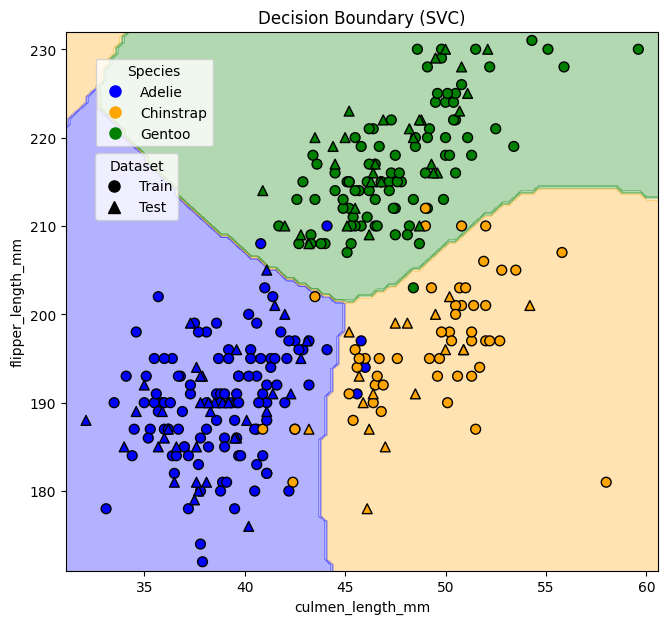

In [48]:
from sklearn.inspection import DecisionBoundaryDisplay
from matplotlib.colors import ListedColormap
import matplotlib.lines as mlines


# Convert labels to numeric
label_map = {'Adelie': 0, 'Chinstrap': 1, 'Gentoo': 2}
y_train_num = y_train.map(label_map)
y_test_num = y_test.map(label_map)

# Define colormap
cmap = ListedColormap(["blue", "orange", "green"])

# Create figure
fig, ax = plt.subplots(figsize=(15, 7))
fig.subplots_adjust(right=0.52)  # leave room for legends on the right

#Plot decision boundary
DecisionBoundaryDisplay.from_estimator(
    pipeline,
    X,
    response_method="predict",
    cmap=cmap,
    alpha=0.3,
    ax=ax
)

# Plot training data (circles)
plt.scatter(
    X_train['culmen_length_mm'],
    X_train['flipper_length_mm'],
    c=y_train_num,
    cmap=cmap,
    edgecolor="k",
    marker='o',
    s=50,)

# Plot test data (triangles)
plt.scatter(
    X_test['culmen_length_mm'],
    X_test['flipper_length_mm'],
    c=y_test_num,
    cmap=cmap,
    edgecolor="k",
    marker='^',
    s=50,
)


# Legend for species (colors)
species_legend = [
    mlines.Line2D([], [], color='blue', marker='o', linestyle='None', markersize=8, label='Adelie'),
    mlines.Line2D([], [], color='orange', marker='o', linestyle='None', markersize=8, label='Chinstrap'),
    mlines.Line2D([], [], color='green', marker='o', linestyle='None', markersize=8, label='Gentoo')
]

# Legend for dataset split (markers)
dataset_legend = [
    mlines.Line2D([], [], color='black', marker='o', linestyle='None', markersize=8, label='Train'),
    mlines.Line2D([], [], color='black', marker='^', linestyle='None', markersize=8, label='Test')
]

legend1 = ax.legend(
    handles=species_legend,
    title="Species",
    loc='upper left',
    bbox_to_anchor=(0.05, 0.95),
    borderaxespad=0.0
)
ax.add_artist(legend1)

ax.legend(
    handles=dataset_legend,
    title="Dataset",
    loc='lower right',
    bbox_to_anchor=(0.19, 0.65),
    borderaxespad=0.0
)

ax.set_xlabel('culmen_length_mm')
ax.set_ylabel('flipper_length_mm')
ax.set_title('Decision Boundary (SVC)')

plt.show()



### Obervations on the Decision Boundary

The decision boundary plot further reinforces our initial observations:
1. Adelies are located at the region with short culmen and short flippers, Gentoos are located at the region with long flippers in general, and Chinstraps are located at the region with longer culmen length but shorter flippers. Minor misclassifications occured near the class boundaries, as discussed in the confusion matric earlier as well.

3. We can also see that the boundaries are non-linear and curved. This is because we used a non-linear RBF kernel. This is expected since the classes are not linearly separable.
